# G10 — Ophiolite emplacement paleo-map

**Cluster G: Paleo-geography + paleo-topography.**

Ophiolites are fragments of oceanic lithosphere obducted onto a continental margin during arc-continent or continent-continent collision. The age at which an ophiolite was exhumed onto the margin is a mappable record of ocean closure — every ophiolite-bearing suture marks a place and time where an ocean basin, or part of one, disappeared. Plotted through time on a paleogeographic reconstruction, the sutures trace the closure of Wilson-cycle oceans across the Phanerozoic.

This notebook uses the global compilation of ophiolite-bearing sutures of Macdonald, Swanson-Hysell, Park, Lisiecki & Jagoutz (2019): 115 sutures, each mapped as a line, with the age ranges of ophiolite crystallisation, of metamorphism in the ophiolite sole, and of ophiolite exhumation (the arc-continent collision), and the references they are based on.

## What this notebook produces

1. **§3 — Paleogeographic map of one age.** The sutures whose ophiolites had been exhumed by the target age, reconstructed to that age on the Zahirovic 2022 model: red where exhumation was under way at that age, grey where it had finished.
2. **§4 — Snapshot series.** The same map at five ages (400, 300, 200, 100, 20 Ma).
3. **§5 — Suture activity through time.** The total length of sutures in their exhumation interval, per 10-Myr bin from 850 Ma to today.

## Learning objectives

- Load a line dataset with age attributes, assign plate IDs by point-in-polygon against the Z22 static polygons, and rotate whole lines with each line's plate.
- Filter a dataset by age (only plot sutures whose ophiolites had been exhumed by the target age).
- Turn age intervals into an activity time series (length of sutures active in each time bin).

## Prerequisites and runtime

- **Plate model**: Zahirovic 2022 (0–410 Ma), mantle frame.
- **Data**: the suture compilation of Macdonald et al. (2019), downloaded on first run from the authors' repository (https://github.com/Swanson-Hysell-Group/Arc_Continent_Analysis, commit `a927d06`) into `cache/macdonald2019_sutures/`.
- **Python**: `gplately`, `pygmt`, `pygplates`, `pandas`, `numpy`, `geopandas`.
- **Runtime**: \~1 minute.


## Environment + imports


In [1]:
from pathlib import Path
import os, sys
if Path("../data").exists() and not Path("data").exists():
    os.chdir("..")

import numpy as np
import pandas as pd
import pygmt
import gplately
import pygplates
from plate_model_manager import PlateModelManager
import sys as _sys
from pathlib import Path as _P
for _d in (_P("Notebooks"), _P("."), _P("../Notebooks")):
    if (_d / "pmm_local.py").exists():
        _sys.path.insert(0, str(_d.resolve())); break
from pmm_local import LocalFirstPMM   # uses the local cache if the model server is unreachable

print("Environment")
print(f"  python      {sys.version.split()[0]}")
for _m in (np, pd, pygmt, gplately, pygplates):
    print(f"  {_m.__name__:11s} {getattr(_m, '__version__', 'n/a')}")


Environment
  python      3.13.18
  numpy       2.5.3
  pandas      3.0.5
  pygmt       v0.19.0
  gplately    2.0.0
  pygplates   1.0.0


In [2]:
# === USER CONFIGURATION =====================================================
MODEL_NAME          = "Zahirovic2022"            # PMM ID
ANCHOR_PLATE_ID     = 0                          # mantle frame — appropriate for
                                                 # tectonic-only (non-paleoclimate) work

# The single-age map in §3
RECONSTRUCTION_TIME = 90.0                       # Ma; Neo-Tethyan ophiolite exhumation

# Snapshot ages for §4
SNAPSHOT_AGES_MA    = [400, 300, 200, 100, 20]

# Suture compilation of Macdonald et al. (2019), pinned to the published commit
SUTURE_URL = ("https://raw.githubusercontent.com/Swanson-Hysell-Group/Arc_Continent_Analysis/"
              "a927d06ca04ffb71215d3e28558083e1c178f042/data/sutures/")
SUTURE_FILES = ["Suture_Lines.shp", "Suture_Lines.shx", "Suture_Lines.dbf", "Suture_Lines.prj", "Suture_Lines.cpg"]
CACHE_DIR    = Path("cache/macdonald2019_sutures")

# Activity time series in §5
HIST_BIN_MA  = 10
HIST_MAX_MA  = 850
# ============================================================================
print(f"  model:        {MODEL_NAME}")
print(f"  anchor:       {ANCHOR_PLATE_ID}")
print(f"  target time:  {RECONSTRUCTION_TIME} Ma")
print(f"  snapshots:    {SNAPSHOT_AGES_MA}")
print(f"  time series:  {HIST_BIN_MA}-Myr bins, 0-{HIST_MAX_MA} Ma")

  model:        Zahirovic2022
  anchor:       0
  target time:  90.0 Ma
  snapshots:    [400, 300, 200, 100, 20]
  time series:  10-Myr bins, 0-850 Ma


## 1. Load the suture compilation


In [3]:
# Download the shapefile once into cache/ (not part of the repository), then read it
import urllib.request
import geopandas as gpd

CACHE_DIR.mkdir(parents=True, exist_ok=True)
for name in SUTURE_FILES:
    dst = CACHE_DIR / name
    if not dst.exists():
        urllib.request.urlretrieve(SUTURE_URL + name, dst)
sut = gpd.read_file(CACHE_DIR / "Suture_Lines.shp")
# EXMAX/EXMIN: ophiolite exhumation (collision) interval; MAGMAX/MAGMIN: ophiolite crystallisation;
# METMAX/METMIN: metamorphism of the ophiolite sole (all in Ma)
print(f"  {len(sut)} ophiolite-bearing sutures, {sut['LENGTH_KM'].sum():,.0f} km in all")
print(f"  exhumation ages: {sut['EXMIN'].min()}–{sut['EXMAX'].max()} Ma; "
      f"{int((sut['EXMAX'] <= 410).sum())} sutures began exhumation within the 410 Myr of Z22")
sut[["NAME", "EXMAX", "EXMIN", "MAGMAX", "MAGMIN", "LENGTH_KM", "REF"]].head()

  115 ophiolite-bearing sutures, 142,371 km in all
  exhumation ages: 0–850 Ma; 82 sutures began exhumation within the 410 Myr of Z22


,NAME,EXMAX,EXMIN,MAGMAX,MAGMIN,LENGTH_KM,REF
0,Quetta,66,49,80,65,1279,Beck et al. (1995)
1,Tsangpo,50,0,165,120,2698,Jagoutz et al. (2015); Hebert et al. (2012)
2,NewGuinea,15,0,190,56,1996,Baldwin et al. (2012); Cloos et al. (2005)
3,Cyclops,4,0,43,29,310,Monnier et al. (1999a)
4,Halmahera,4,0,165,66,595,Hall et al. (1988); Ballantyne (1996)


## 2. Build the plate model + assign plate IDs


In [4]:
pmm   = LocalFirstPMM()
model = pmm.get_model(MODEL_NAME, data_dir="data/pmm_cache")

recon = gplately.PlateReconstruction(
    rotation_model=model.get_rotation_model(),
    topology_features=model.get_topologies(),
    static_polygons=model.get_static_polygons(),
    anchor_plate_id=ANCHOR_PLATE_ID,
)
gplot = gplately.PlotTopologies(
    plate_reconstruction=recon,
    coastlines=model.get_layer("Coastlines"),
    plot_engine=gplately.PygmtPlotEngine(),
    continents=model.get_layer("ContinentalPolygons"),
    COBs=model.get_layer("COBs") if "COBs" in model.get_avail_layers() else None,
    time=RECONSTRUCTION_TIME,
    anchor_plate_id=ANCHOR_PLATE_ID,
)

# Each suture moves with the plate under its midpoint (point-in-polygon against the static polygons)
MAX_MODEL_AGE = float(model.get_big_time())
map_sut = sut[sut["EXMAX"] <= MAX_MODEL_AGE].reset_index(drop=True)
mid = [g.interpolate(0.5, normalized=True) for g in map_sut.geometry]   # midpoint along the line (lon/lat)
pts = gplately.Points(plate_reconstruction=recon, lons=[m.x for m in mid], lats=[m.y for m in mid],
                      time=0, anchor_plate_id=ANCHOR_PLATE_ID)
map_sut["plate_id"] = np.asarray(pts.plate_id, dtype=int)
print(f"  assigned plate IDs to {len(map_sut)} sutures exhumed since {MAX_MODEL_AGE:.0f} Ma "
      f"({map_sut['plate_id'].nunique()} plates)")

  assigned plate IDs to 82 sutures exhumed since 410 Ma (74 plates)


## 3. Reconstruct to the target age + plot on a paleogeographic reconstruction

A suture appears on a map of age *t* only once its ophiolites had begun to be exhumed (`EXMAX` ≥ *t*); it is drawn red while exhumation was under way (`EXMAX` ≥ *t* ≥ `EXMIN`) and grey once it had finished. Each suture line is rotated from its present position to *t* with the rotation of its plate.


In [5]:
def reconstruct_line(geom, plate_id, t):
    """Rotate a present-day suture line to time t with its plate's finite rotation.
    Returns a list of (lon, lat) segments: the line is split where it crosses the dateline."""
    rot = recon.rotation_model.get_rotation(float(t), int(plate_id), anchor_plate_id=ANCHOR_PLATE_ID)
    lonlat = [(rot * pygplates.PointOnSphere(y, x)).to_lat_lon()[::-1] for x, y in geom.coords]
    lon, lat = np.array(lonlat).T
    cut = np.where(np.abs(np.diff(lon)) > 180)[0] + 1
    return [(x, y) for x, y in zip(np.split(lon, cut), np.split(lat, cut)) if len(x) > 1]

def sutures_at(t):
    """Sutures exhumed by time t, with their reconstructed lines and state at t."""
    s = map_sut[map_sut["EXMAX"] >= t].copy()
    s["active"] = s["EXMIN"] <= t
    s["line"] = [reconstruct_line(g, pid, t) for g, pid in zip(s.geometry, s["plate_id"])]
    return s

now = sutures_at(RECONSTRUCTION_TIME)
print(f"  {len(now)} sutures exhumed by {RECONSTRUCTION_TIME:.0f} Ma, "
      f"{int(now['active'].sum())} of them with exhumation under way at that age")

  48 sutures exhumed by 90 Ma, 12 of them with exhumation under way at that age


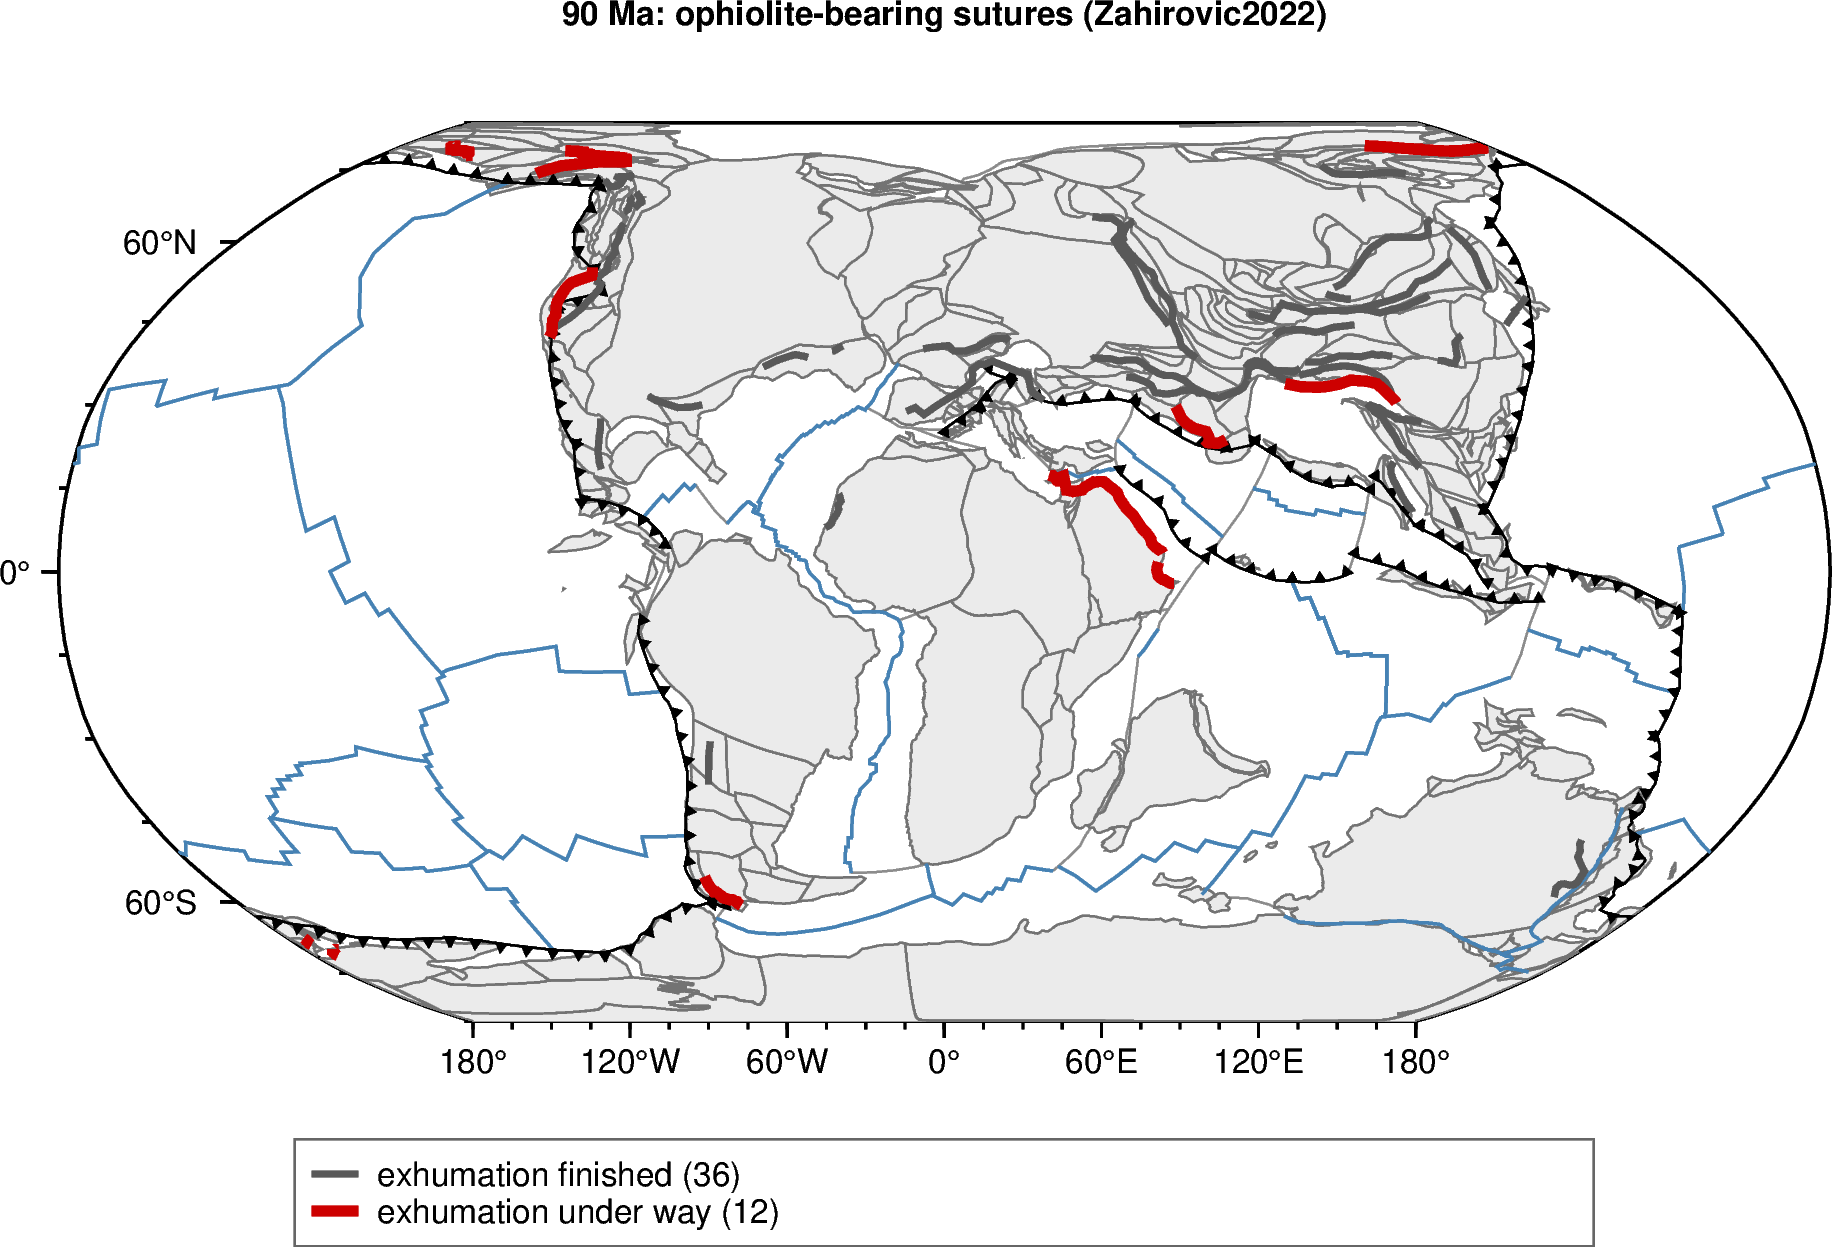

In [6]:
REGION, PROJ = [-180, 180, -90, 90], "N15c"

def suture_map(t, s, width=1000):
    """One paleogeographic map at time t with the sutures in s."""
    gplot.time = float(t)
    fig = pygmt.Figure()
    fig.basemap(region=REGION, projection=PROJ,
                frame=["af", f"+t{t:.0f} Ma: ophiolite-bearing sutures ({MODEL_NAME})"])
    gplot.plot_all_topological_sections(fig, pen="0.5p,gray55")
    gplot.plot_continents(fig, fill="gray92", pen="0.5p,gray45")
    gplot.plot_ridges(fig, pen="0.7p,steelblue")
    gplot.plot_subduction_teeth(fig, color="black")
    first = {True: True, False: True}
    for active, pen, lab in ((False, "1.6p,gray35", "exhumation finished"),
                             (True, "2.6p,red3", "exhumation under way")):
        for segments in s.loc[s["active"] == active, "line"]:
            for lon, lat in segments:
                fig.plot(x=lon, y=lat, pen=pen,
                         label=f"{lab} ({int((s['active'] == active).sum())})" if first[active] else None)
                first[active] = False
    if len(s):
        fig.legend(position="JBC+jTC+o0/1.0c+w11c", box="+gwhite+p0.5p,gray40")
    fig.show(width=width)

suture_map(RECONSTRUCTION_TIME, now)

### How to read the paleo-map

- **Red lines** — sutures whose ophiolites were being exhumed onto the margin at `RECONSTRUCTION_TIME`: collisions under way at that age.
- **Grey lines** — sutures whose exhumation had finished: older collision zones carried along with their plates.
- **Black teeth / blue lines** — the subduction zones and ridges of the plate model at that age, for comparison with where the collisions were happening.

At 90 Ma, look for the Neo-Tethyan sutures along the southern margin of Eurasia and the northern margin of Arabia and India, and compare their positions with the contemporaneous subduction zones.


## 4. Snapshot series — five ages

Same rendering as §3 at the ages in `SNAPSHOT_AGES_MA`, to follow ocean closure through time.


  400 Ma: 1 sutures exhumed by then, 1 under way


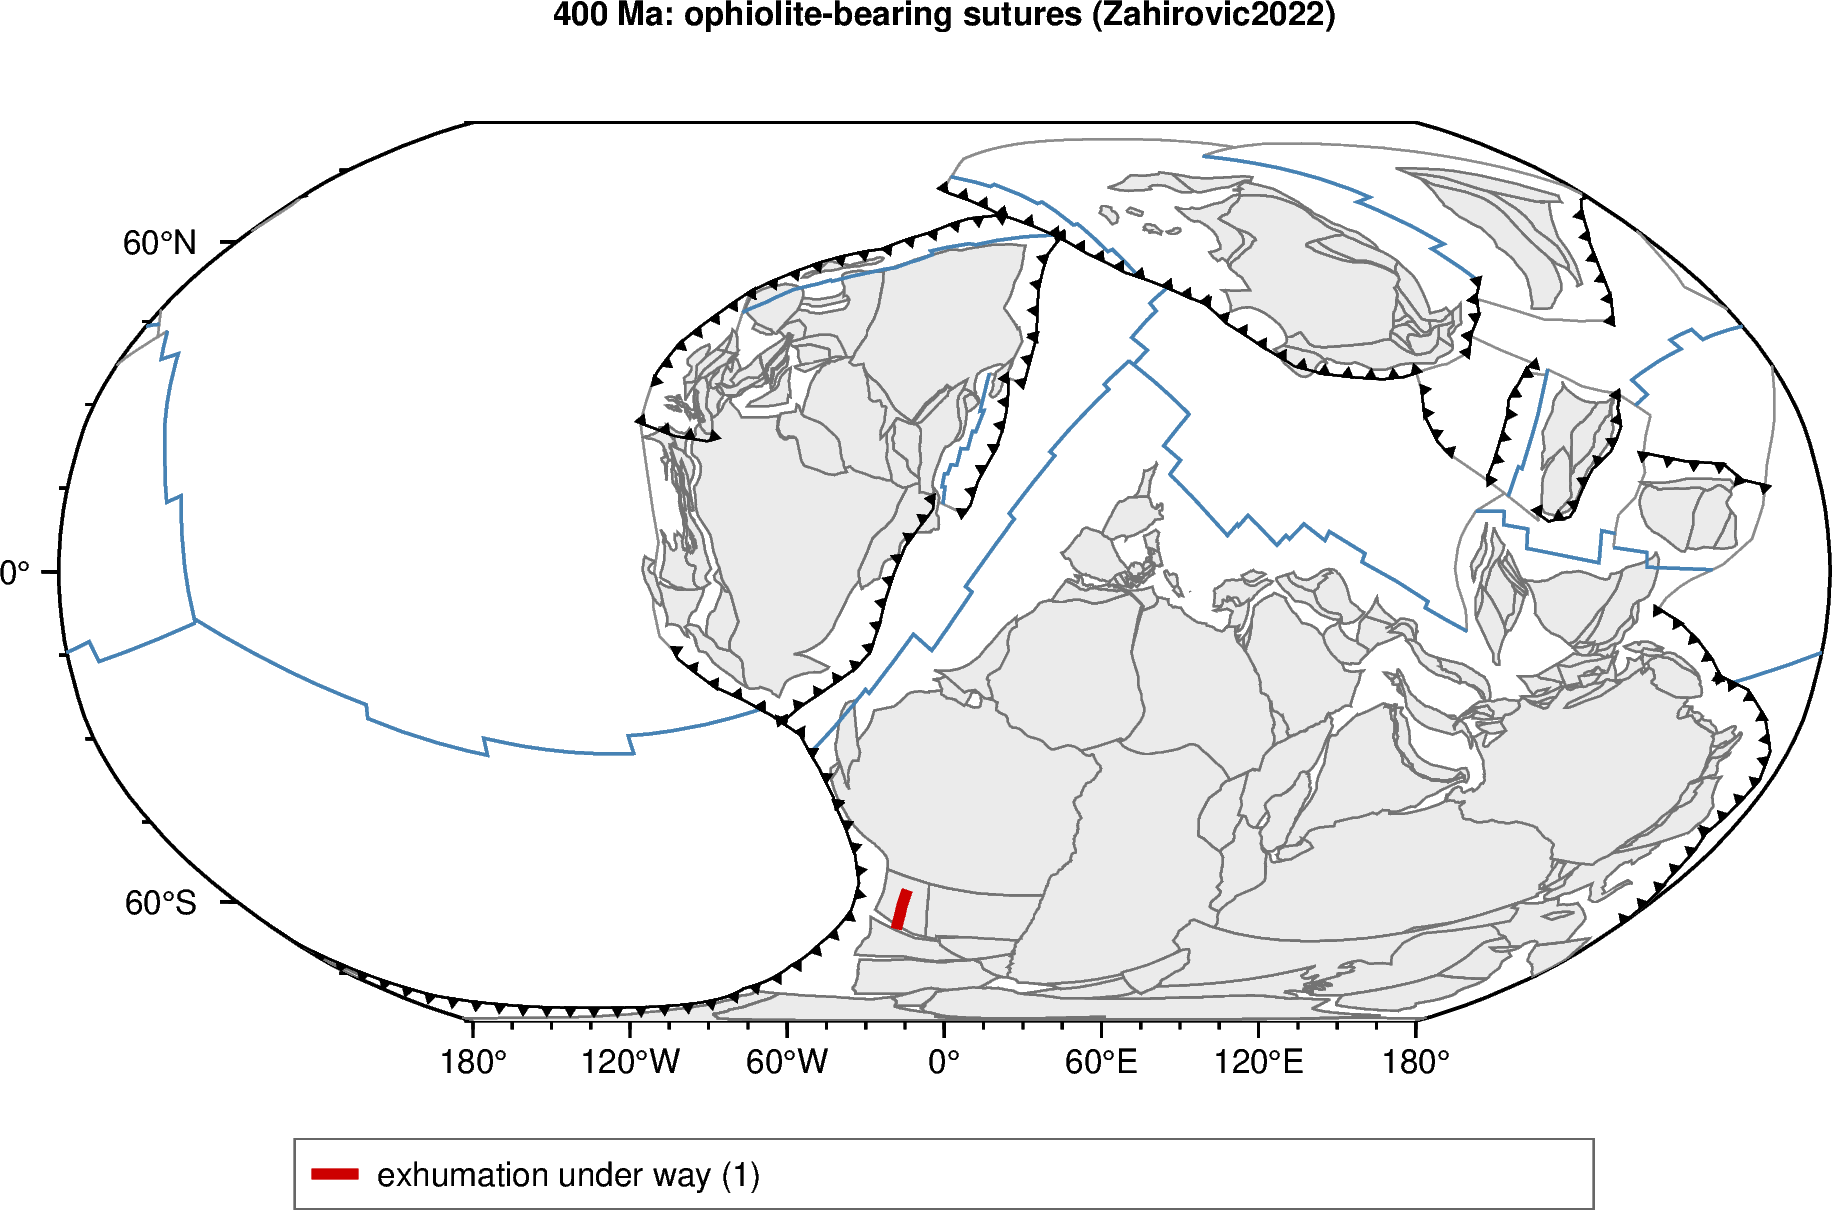

  300 Ma: 14 sutures exhumed by then, 8 under way


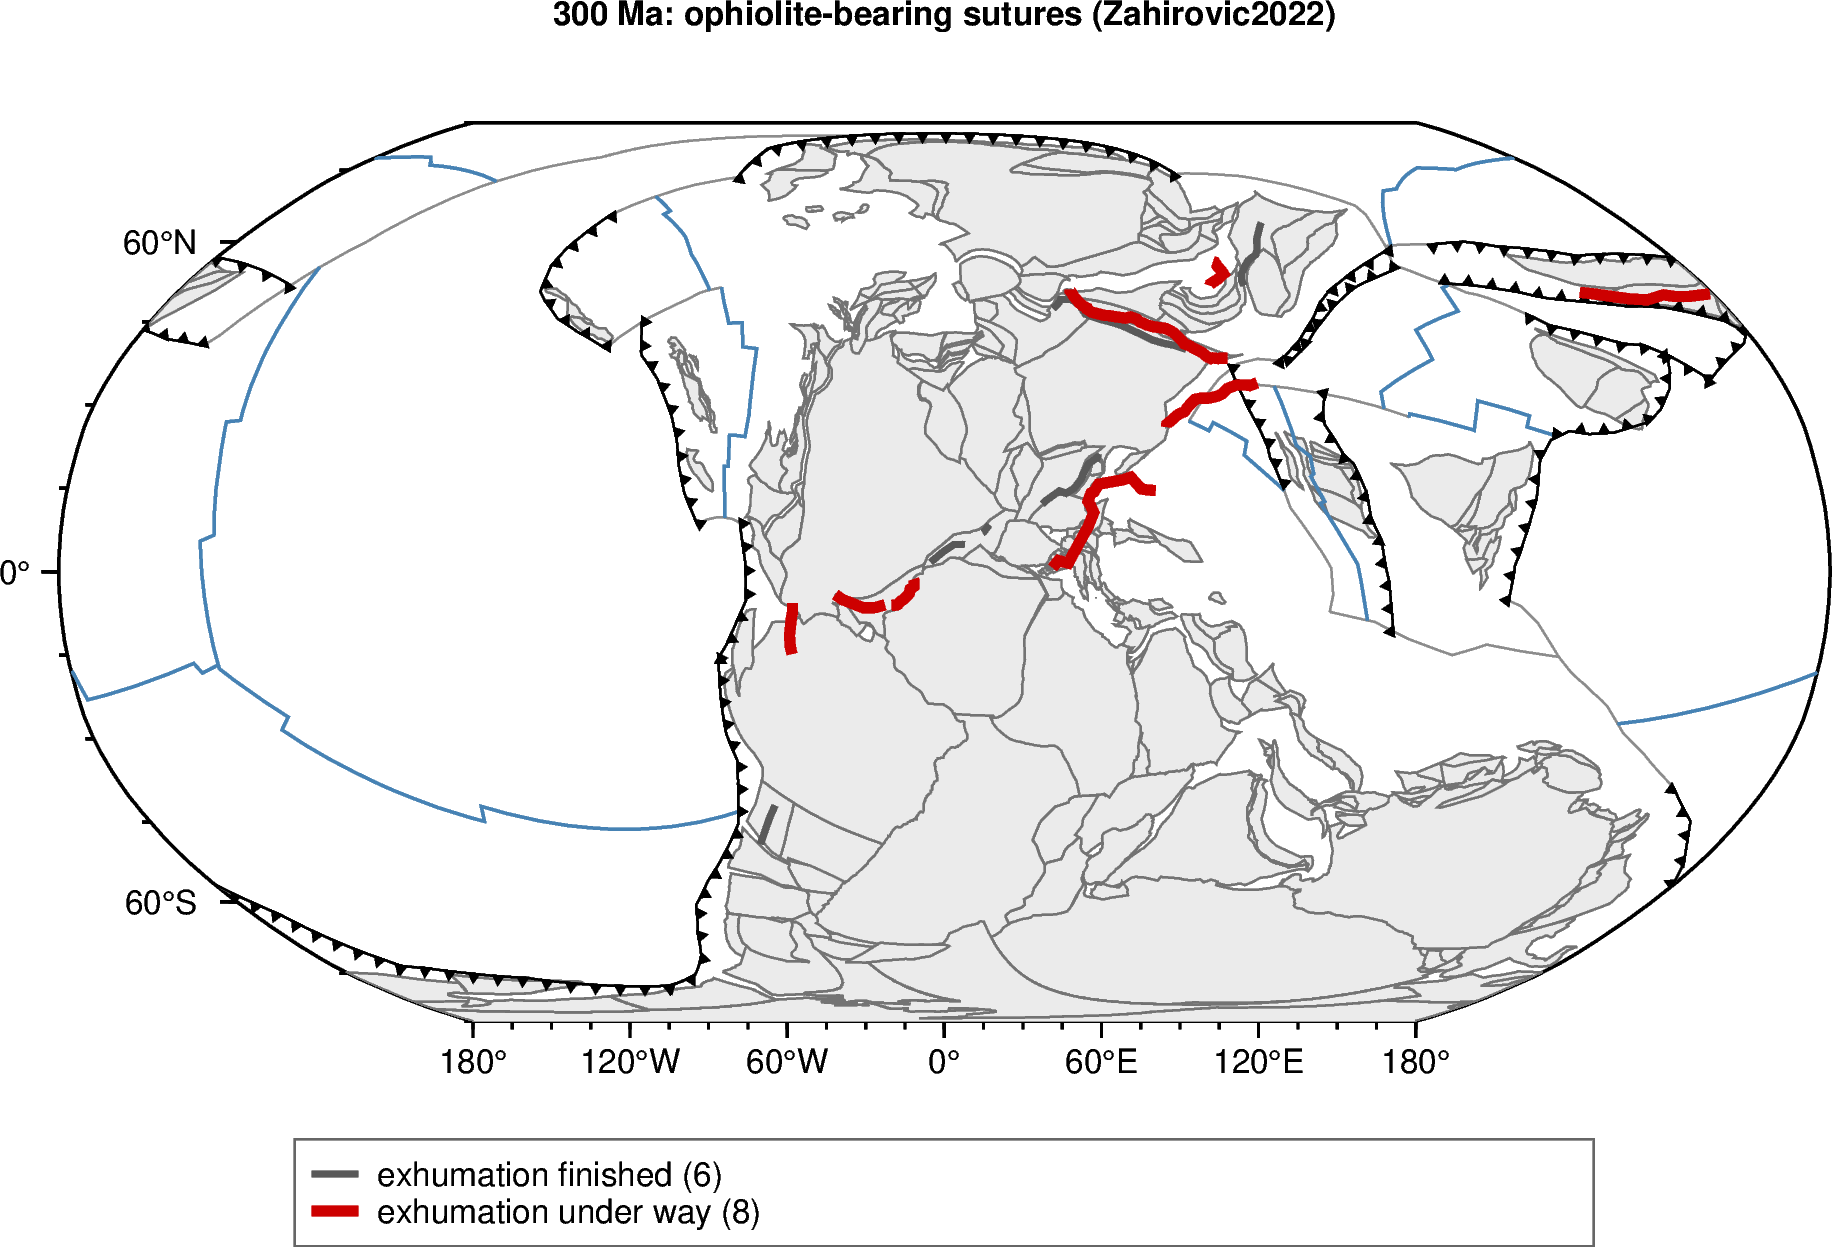

  200 Ma: 32 sutures exhumed by then, 2 under way


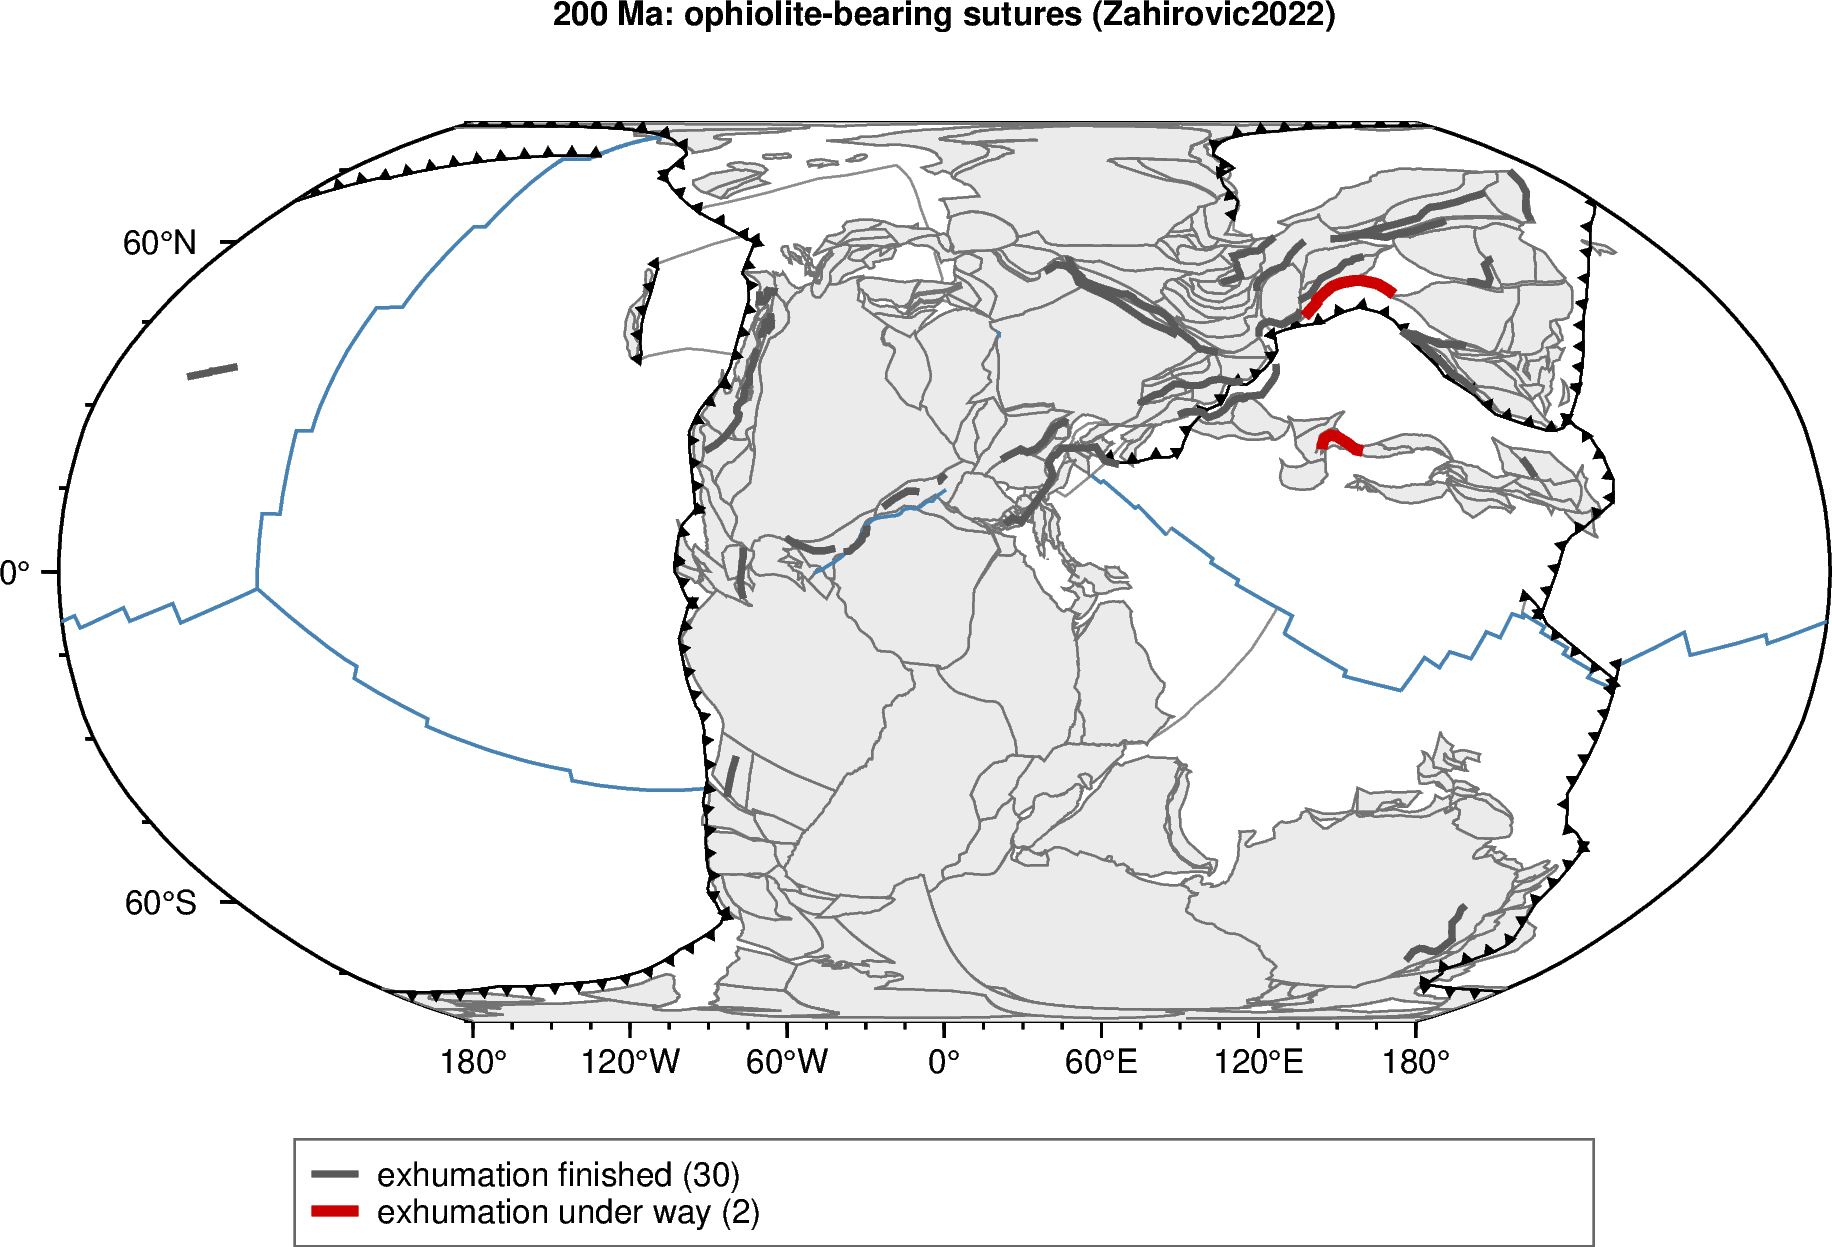

  100 Ma: 43 sutures exhumed by then, 7 under way


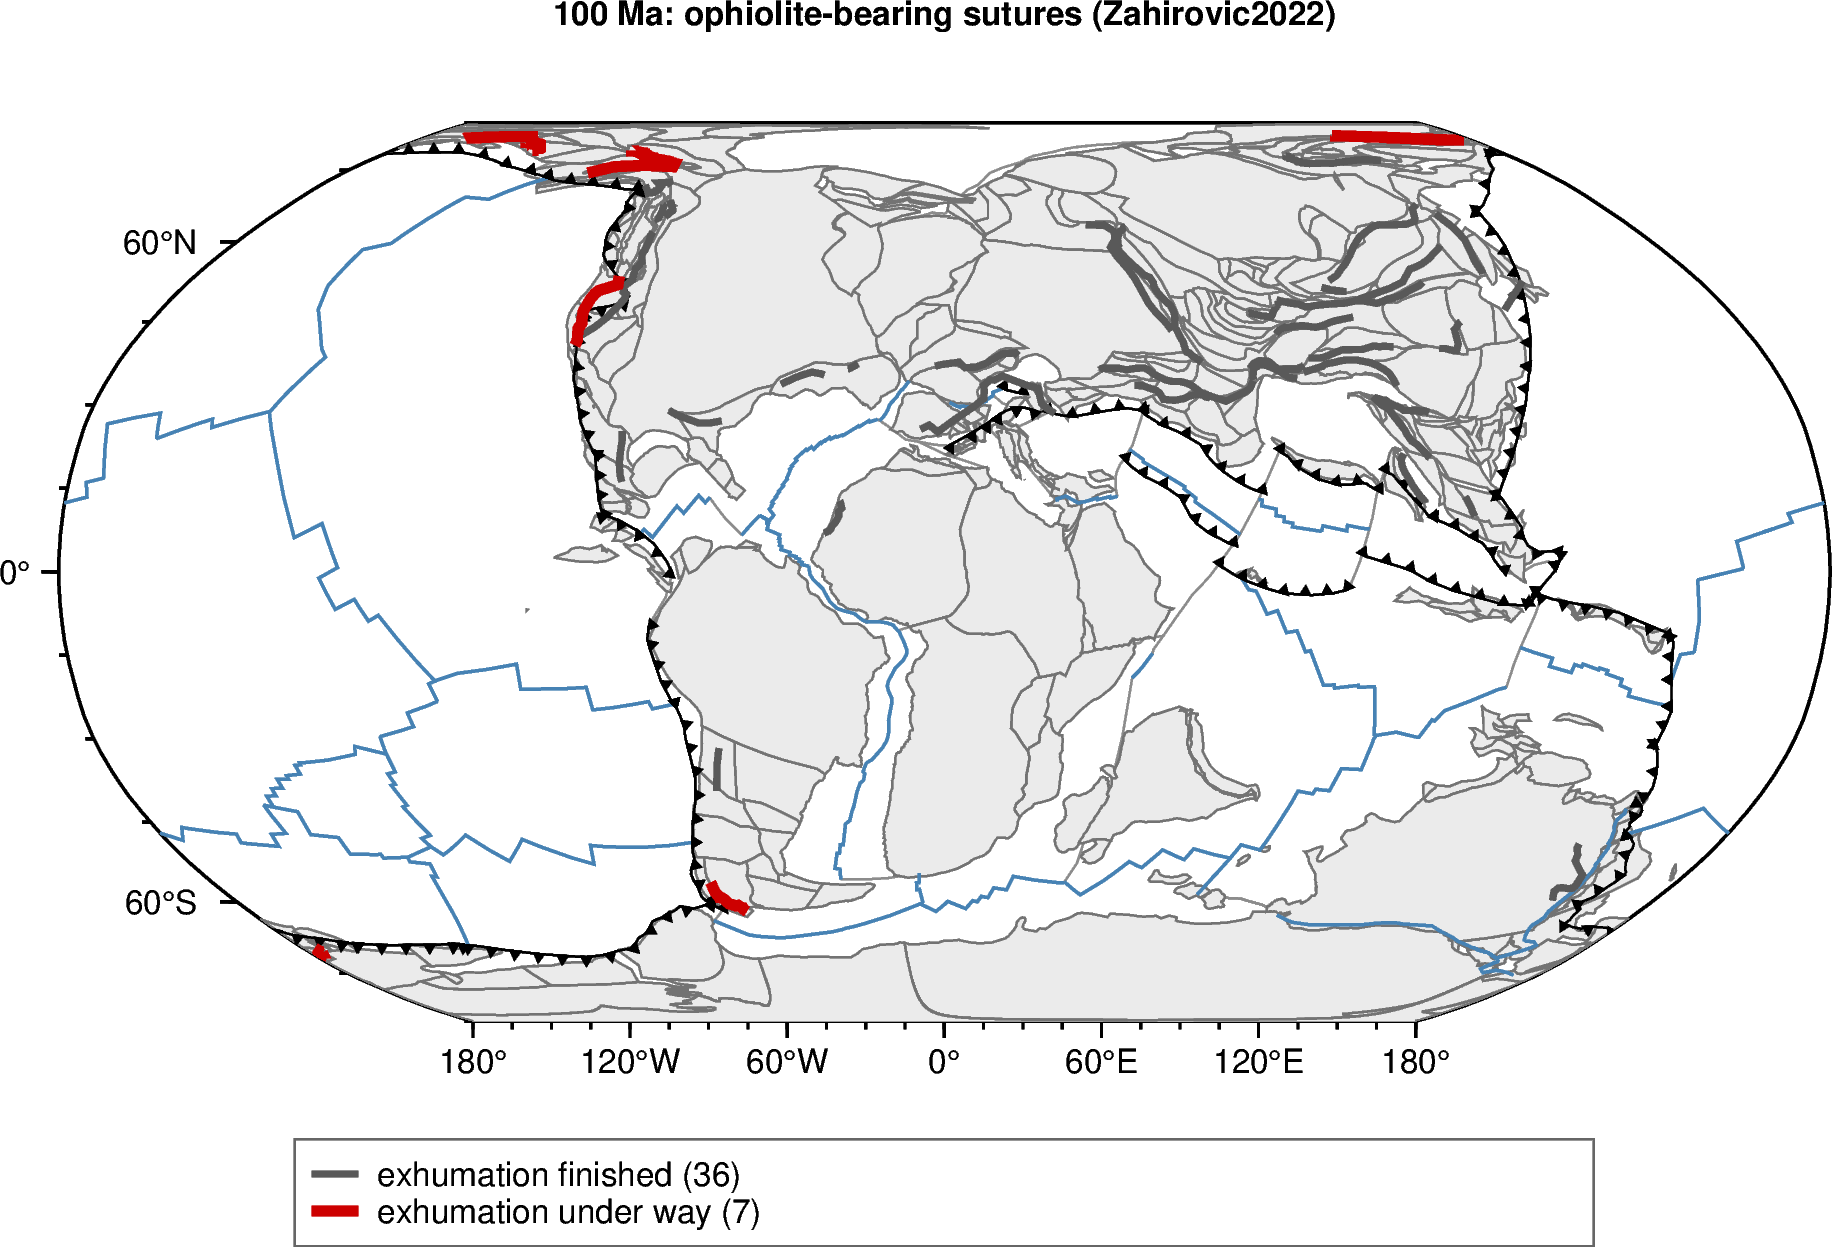

  20 Ma: 70 sutures exhumed by then, 12 under way


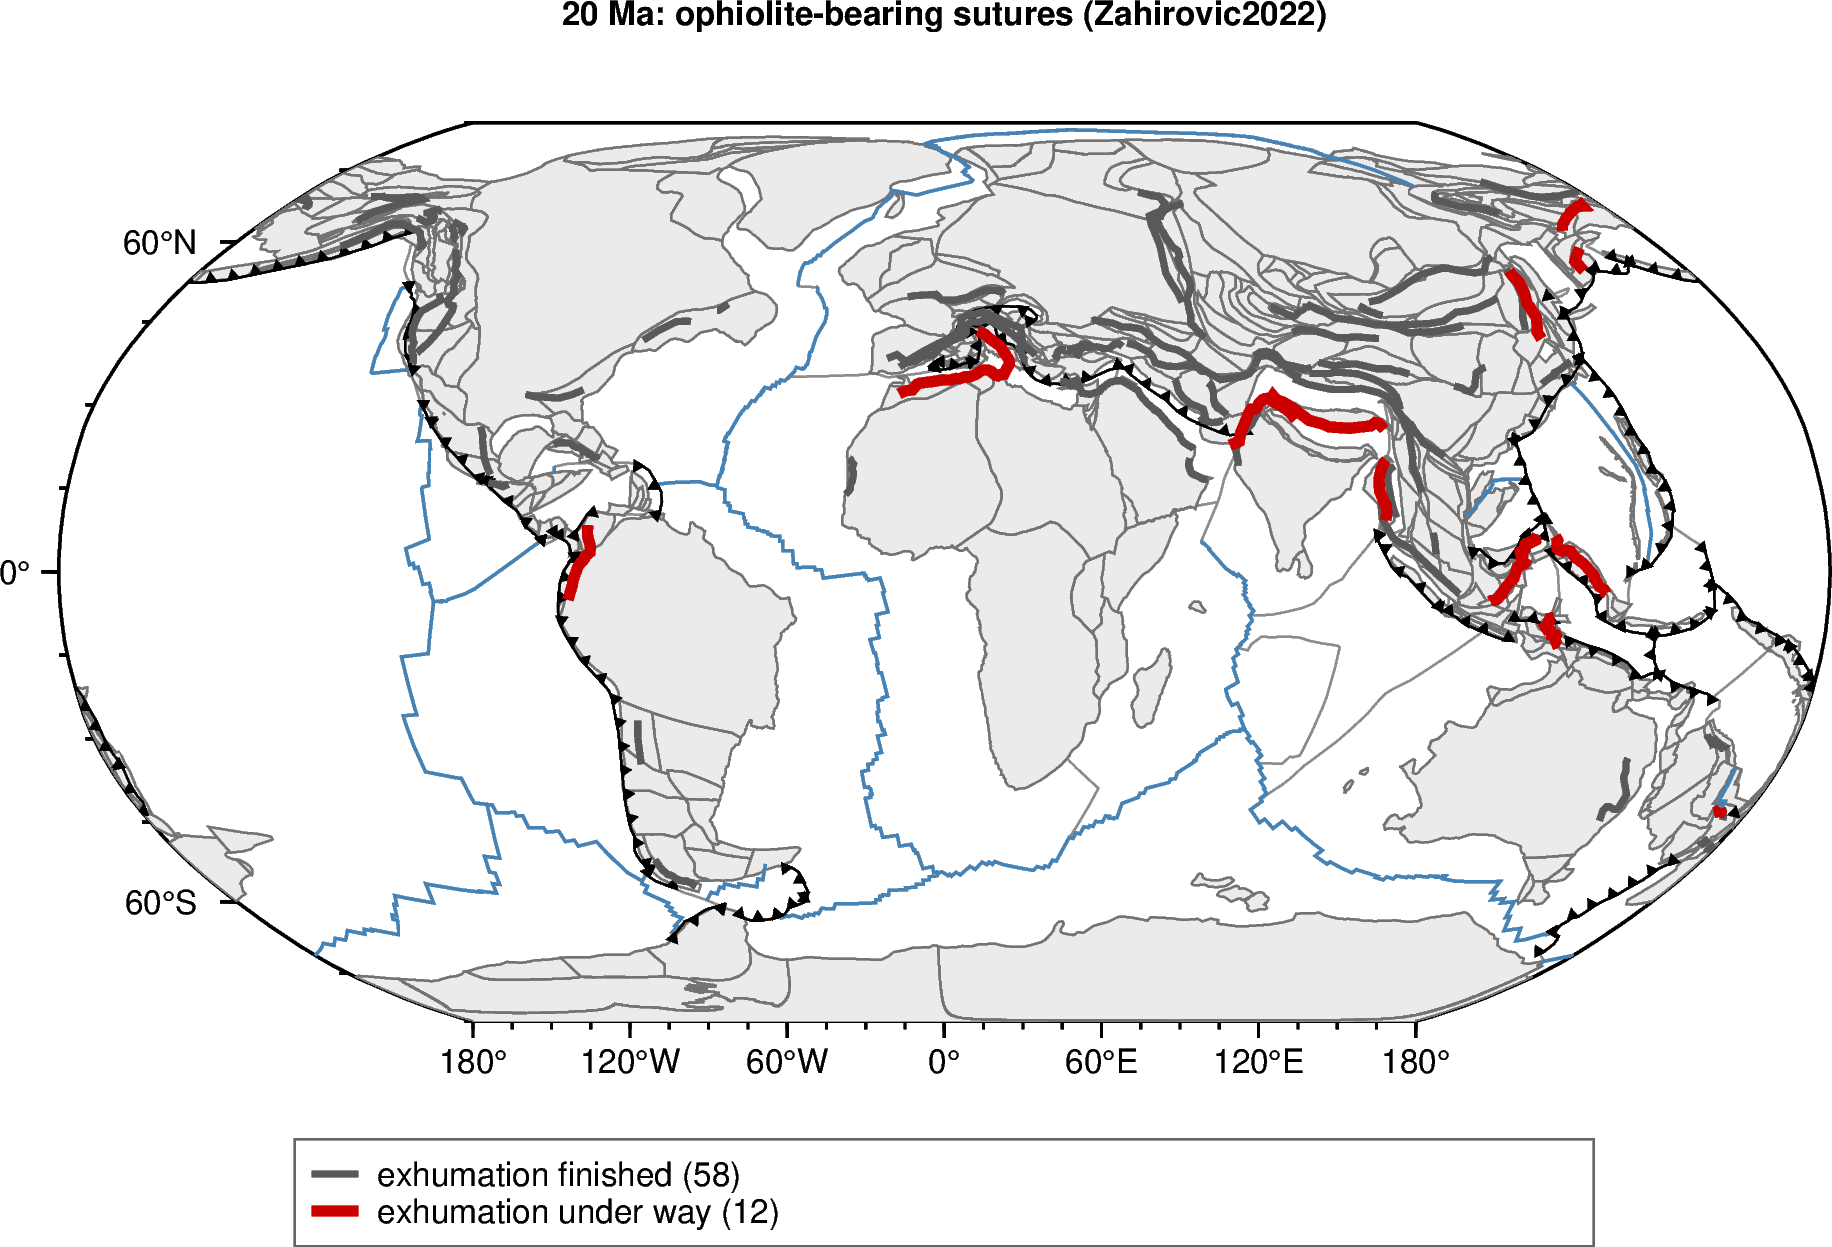

In [7]:
for age in SNAPSHOT_AGES_MA:
    s = sutures_at(age)
    print(f"  {age} Ma: {len(s)} sutures exhumed by then, {int(s['active'].sum())} under way")
    suture_map(age, s, width=900)

### How to read the series

Each map shows the collision zones of its age in red and the older ones in grey. Watch the red lines move from the Paleozoic oceans (Iapetus, Rheic, Paleo-Asian) at 400 and 300 Ma, through Paleo-Tethys and the Cordillera, to the Neo-Tethyan and SW-Pacific collisions at 100 and 20 Ma. Macdonald et al. (2019) used the latitudes of these active sutures to argue that arc-continent collisions in the tropics set Earth's climate state.


## 5. Suture activity through time

For each `HIST_BIN_MA`-Myr bin, the total length of sutures whose exhumation interval overlaps the bin. Uses the whole compilation (back to 850 Ma), beyond the 410 Myr of the paleo-maps.


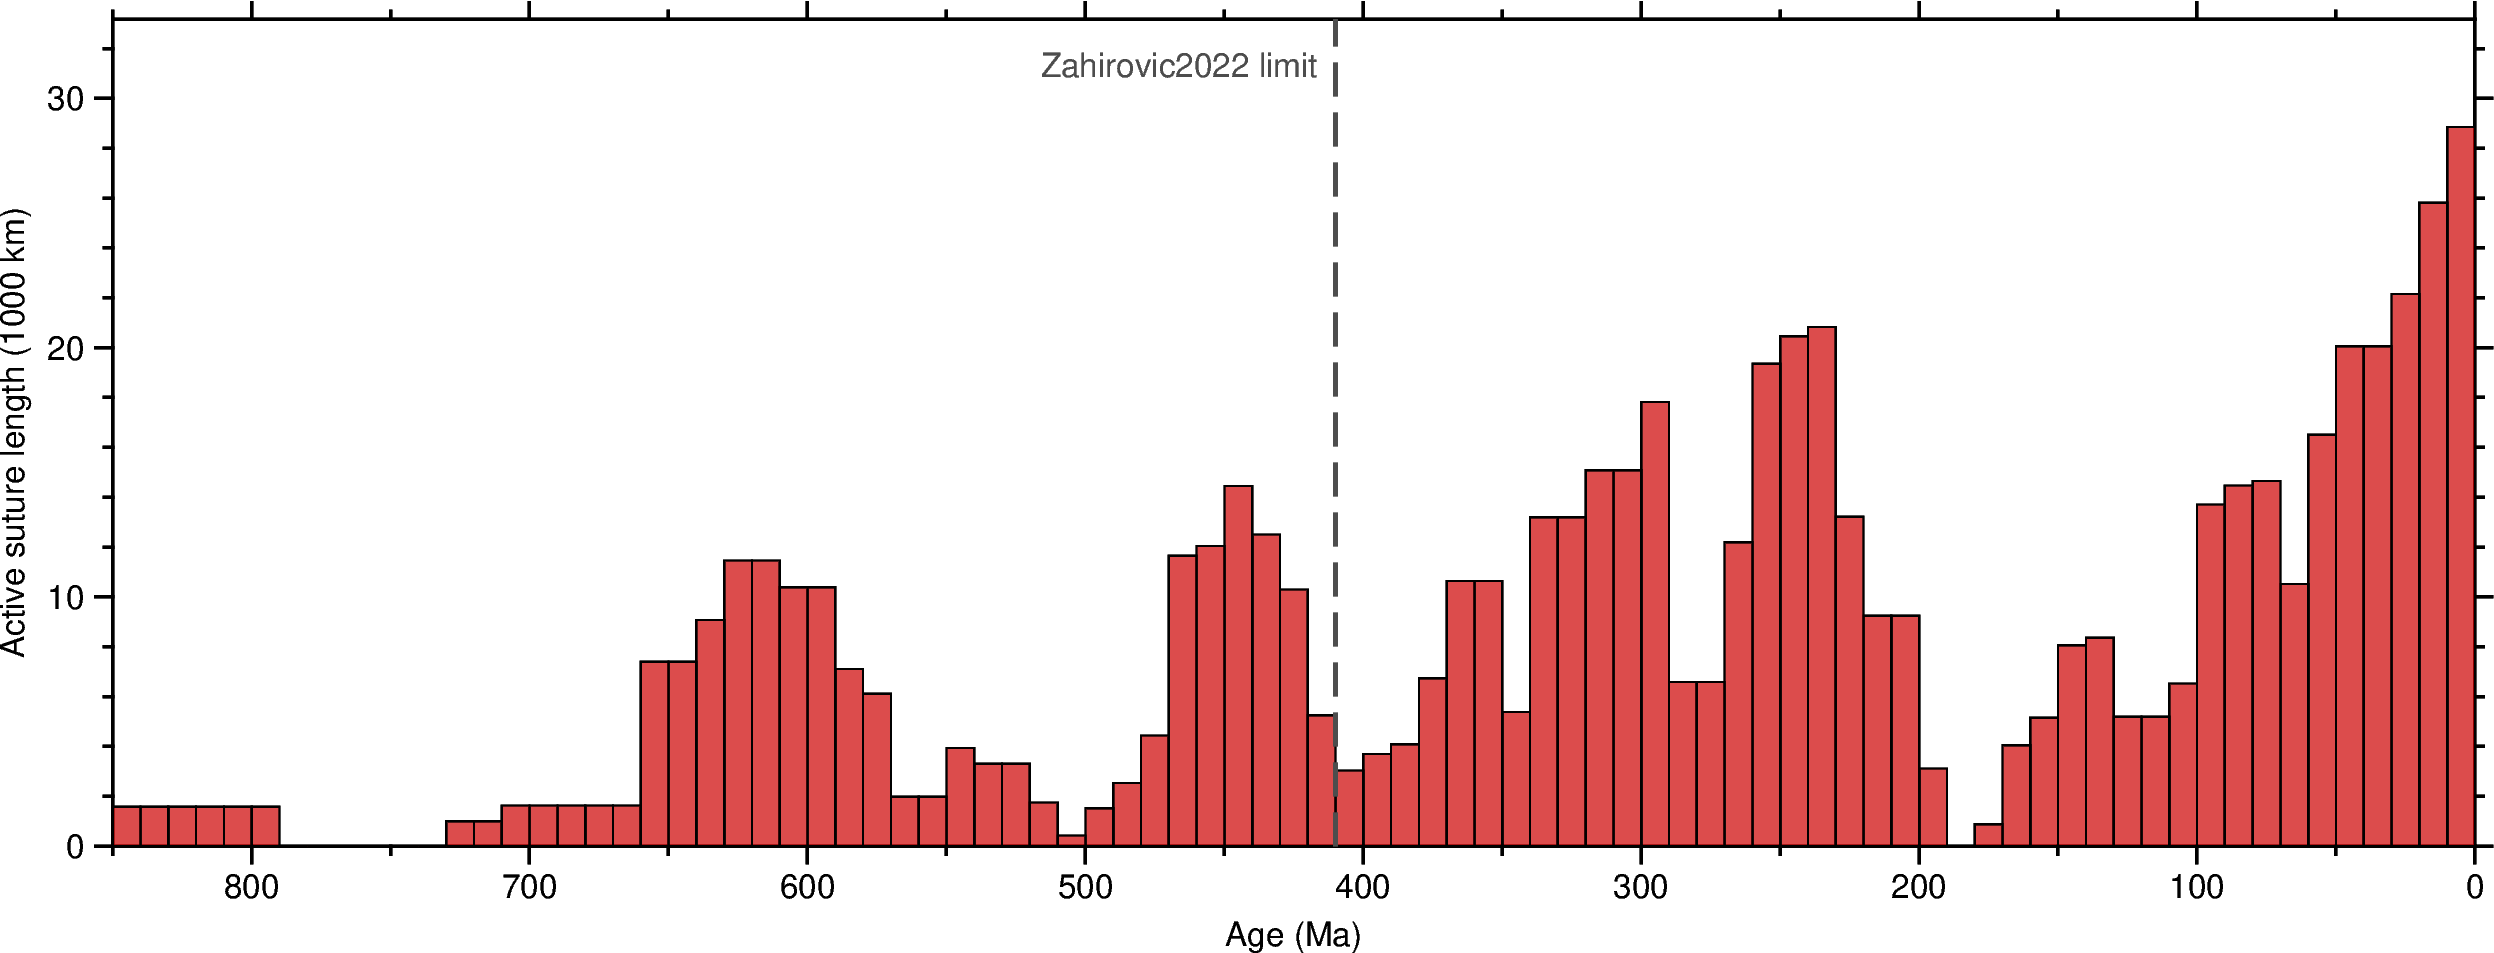

  peak: 28.8 thousand km active in 0–10 Ma


In [8]:
edges = np.arange(0, HIST_MAX_MA + HIST_BIN_MA, HIST_BIN_MA)
active_km = np.array([sut.loc[(sut["EXMAX"] >= lo) & (sut["EXMIN"] <= hi), "LENGTH_KM"].sum()
                      for lo, hi in zip(edges[:-1], edges[1:])]) / 1000.0
centres = 0.5 * (edges[:-1] + edges[1:])
ymax = float(active_km.max()) * 1.15

fig = pygmt.Figure()
fig.basemap(region=[0, HIST_MAX_MA, 0, ymax], projection="X-20c/7c",
            frame=["WSne", "xa100f50+lAge (Ma)", f"yaf+lActive suture length (1000 km)"])
fig.plot(x=centres, y=active_km, style=f"b{HIST_BIN_MA}u+b0", fill="red3@30", pen="0.4p,black")
fig.plot(x=[MAX_MODEL_AGE, MAX_MODEL_AGE], y=[0, ymax], pen="1p,gray30,-")
fig.text(x=MAX_MODEL_AGE, y=ymax * 0.93, text=f"{MODEL_NAME} limit", font="8p,Helvetica,gray30",
         justify="RB", offset="-0.15c/0c")
fig.show(width=1100)
print(f"  peak: {active_km.max():.1f} thousand km active in {edges[active_km.argmax()]:.0f}–"
      f"{edges[active_km.argmax()] + HIST_BIN_MA:.0f} Ma")

### How to read the time series

The bars give the length of ophiolite-bearing sutures in their exhumation interval in each 10-Myr bin: the global length of active arc-continent collision zones recorded by ophiolites. Peaks mark intervals of widespread ocean closure. Read the bars against the paleo-maps above, and against the climate record, as Macdonald et al. (2019) did.


## Extend this

- **Paleo-latitude of active sutures.** Reconstruct each active suture to its exhumation interval and record its paleo-latitude; Macdonald et al. (2019) compared the length of active sutures in the tropics with the extent of continental ice.
- **Use the crystallisation ages.** Replace `EXMAX`/`EXMIN` by `MAGMAX`/`MAGMIN` to map when the ophiolites formed rather than when they were emplaced.
- **Another plate model.** The compilation also carries plate IDs for the Torsvik & Cocks (2017) CEED6 and Matthews et al. (2016) models; in Cao 2024 or Merdith 2021 the maps extend beyond 410 Ma.
- **Cross-reference with the zircon suite (D01-D04).** Ophiolite exhumation intervals can be compared with the age peaks of the Wu et al. (2023) zircon compilation.

## Related notebooks

- **D01-D04** — Wu 2023 zircon compilation on a paleogeographic reconstruction: the same reconstruction-to-paleo-position pattern.
- **J01** — Boucot climate-sensitive lithologies: the same paleo-latitude workflow.

## Sources

- Macdonald, F.A., Swanson-Hysell, N.L., Park, Y., Lisiecki, L. & Jagoutz, O. (2019). Arc-continent collisions in the tropics set Earth's climate state. *Science* 364(6436), 181-184. https://doi.org/10.1126/science.aav5300 — suture compilation: https://github.com/Swanson-Hysell-Group/Arc_Continent_Analysis
- Furnes, H., De Wit, M. & Dilek, Y. (2014). Four billion years of ophiolites reveal secular trends in oceanic crust formation. *Geoscience Frontiers* 5(4), 571-603. doi:10.1016/j.gsf.2014.02.002.
- Dilek, Y. & Furnes, H. (2011). Ophiolite genesis and global tectonics: Geochemical and tectonic fingerprinting of ancient oceanic lithosphere. *Geological Society of America Bulletin* 123(3-4), 387-411. doi:10.1130/B30446.1.
- Zahirovic, S., Eleish, A., Doss, S., Pall, J., Cannon, J., Pistone, M., Tetley, M.G., Young, A. & Fox, P. (2022). Subduction and carbonate platform interactions. *Geoscience Data Journal* 9(2), 371-383. https://doi.org/10.1002/gdj3.146